# The Zhong et al. (2025) dataset

Mice ran through a virtual corridor while two-photon imaging recorded around 70,000 neurons at once across primary visual cortex (V1) and the higher visual areas. Each trial shows one of two wall textures. **Supervised** mice got a sugar-water reward in one corridor; **unsupervised** mice saw the same corridors with no reward. Each mouse was imaged in a session **before** and a session **after** learning.

This notebook shows how the data are organised and how `code/data.py` reads them. Everything comes straight from the public Figshare release (DOI [10.25378/janelia.28811129.v2](https://doi.org/10.25378/janelia.28811129.v2), CC BY 4.0). Tables land in a DuckDB file and large arrays stay as checksum-verified files beside it, in `~/zhong2025` by default (set `ZHONG_DATA` to change it).

Run it from the `notebooks` folder after `pip install duckdb matplotlib numpy pandas requests scikit-learn scipy`. The first run downloads about 4.3 GiB.

In [1]:
%matplotlib inline
import sys
sys.path.append("../code")

import numpy as np
import pandas as pd

import data
import plot

z = data.Zhong()

## The release

The Figshare API lists 297 files. Almost all of the 421 GiB is the full deconvolved activity (`neural_data.npy`). The same activity also ships compressed as a 400-component SVD (`SVD_dec.npy`), and that is what this project uses.

In [2]:
z.sql("""
    SELECT coalesce(nullif(regexp_extract(name, '^[A-Z]+[0-9]+_[0-9]{4}_[0-9]{2}_[0-9]{2}(_[0-9]+)?_(.+)$', 2), ''), 'behaviour bundles and metadata') AS kind,
           count(*) AS files,
           round(sum(size) / 2 ^ 30, 2) AS GiB
    FROM files
    GROUP BY kind
    ORDER BY GiB DESC
""")

,kind,files,GiB
0,neural_data.npy,89,404.36
1,SVD_dec.npy,89,10.01
2,behaviour bundles and metadata,29,6.56
3,trans.npz,89,0.16
4,example_raw_spk.npy,1,0.09


## Sessions

The analysis uses the 13 mice of the first texture-learning experiment: 4 supervised and 9 unsupervised, each with one session before and one after learning. The walls are coded by stimulus role. **leaf** is stimulus 2, the rewarded corridor for supervised mice, and **circle** is stimulus 0. Most mice saw the leaf and circle textures, but a few saw other textures in those roles, as the `leaf` and `circle` columns show.

In [3]:
z.sessions

,session,mouse,condition,phase,leaf,circle,trials,frames
0,TX108_2023_03_13_1,TX108,supervised,before,wood1,rock1,210,22994
1,TX108_2023_03_22_1,TX108,supervised,after,wood1,rock1,300,19567
2,TX109_2023_03_27_1,TX109,supervised,before,circle1,leaf1,84,14587
3,TX109_2023_04_07_1,TX109,supervised,after,circle1,leaf1,320,20022
4,TX60_2021_04_10_1,TX60,supervised,before,leaf1,circle1,237,23470
5,TX60_2021_05_04_1,TX60,supervised,after,leaf1,circle1,303,17578
6,VR2_2021_03_20_1,VR2,supervised,before,leaf1,circle1,348,24300
7,VR2_2021_04_06_1,VR2,supervised,after,leaf1,circle1,470,17761
8,DR10_2022_07_12_1,DR10,unsupervised,before,leaf1,circle1,503,31709
9,DR10_2022_07_19_1,DR10,unsupervised,after,leaf1,circle1,431,22329


In [4]:
z.sql("""
    SELECT s.condition, t.wall = s.leaf AS leaf_corridor, count(*) AS trials,
           round(avg(t.rewarded::INT), 3) AS reward_rate, round(avg(t.licks), 1) AS licks_per_trial
    FROM trials t JOIN sessions s USING (session)
    GROUP BY ALL ORDER BY ALL
""")

,condition,leaf_corridor,trials,reward_rate,licks_per_trial
0,supervised,False,1147,0.000,3.5
1,supervised,True,1125,0.996,15.3
2,unsupervised,False,3117,0.000,0.0
3,unsupervised,True,3126,0.000,0.0


## Behaviour

Every imaging frame has a corridor position, the texture on the walls and the running speed. Positions 0 to 40 are the texture zone and 40 to 60 is a gray zone before the next trial.

In [5]:
session = "VR2_2021_03_20_1"
frames = z.frames(session)
frames.head()

,session,frame,time,trial,position,wall,role,moving,speed
0,VR2_2021_03_20_1,0,0.000000,<NA>,0.0,NaN,NaN,False,0.0
1,VR2_2021_03_20_1,1,0.313386,<NA>,0.0,NaN,NaN,False,0.0
2,VR2_2021_03_20_1,2,0.628029,<NA>,0.0,NaN,NaN,False,0.0
3,VR2_2021_03_20_1,3,0.942511,<NA>,0.0,NaN,NaN,False,0.0
4,VR2_2021_03_20_1,4,1.257990,<NA>,0.0,NaN,NaN,False,0.0


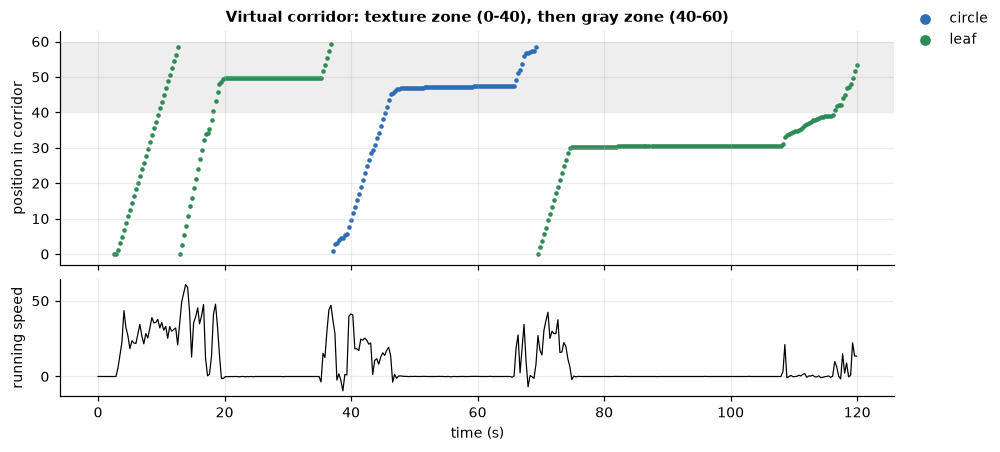

In [6]:
plot.corridor(frames)

## Neurons

`trans.npz` places every neuron on a common cortical map and assigns it to a visual area: V1, or the medial, lateral or anterior higher visual areas (mHV, lHV, aHV). Neurons outside these four have no area.

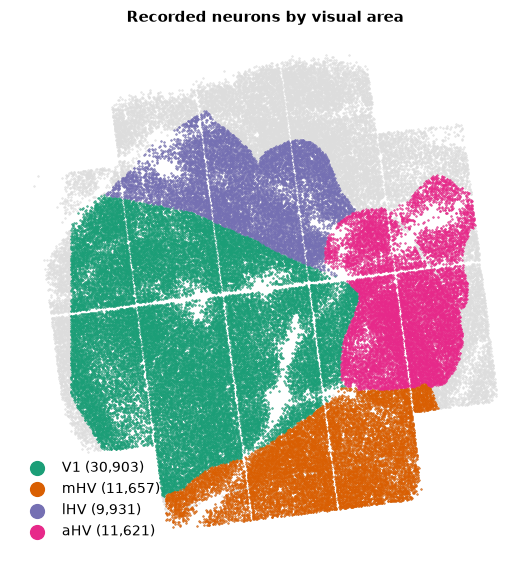

In [7]:
neurons = z.neurons(session)
plot.areas(neurons)

In [8]:
z.sql("""
    SELECT coalesce(area, 'outside the four areas') AS area, count(*) AS neurons, round(count(*) / count(DISTINCT session)) AS per_session
    FROM neurons GROUP BY ALL ORDER BY neurons DESC
""")

,area,neurons,per_session
0,V1,576257,22164.0
1,mHV,351291,13511.0
2,aHV,206070,7926.0
3,outside the four areas,182667,7026.0
4,lHV,148726,5720.0


## Activity

Activity is stored as an SVD: activity ≈ Uᵀ·V, with U of shape (400 components × neurons) and V of shape (400 × frames). `z.activity` rebuilds any block of neurons and frames on demand, so the full matrix (about 70,000 × 20,000 per session) is never held in memory.

In [9]:
U, V = z.svd(session)
U.shape, V.shape

((400, 81473), (400, 24298))

Single neurons are noisy, so the raster shows the 25 most leaf-preferring and the 25 most circle-preferring neurons of each area out of 500 sampled per area. I pick them on the first 3,000 frames and show the next 1,200, so the pattern is not a product of the selection. Within each area the leaf-preferring neurons (top) fire on leaf trials (green) and the circle-preferring neurons (bottom) on circle trials (blue). The strip is gray while the mouse is in the gray zone.

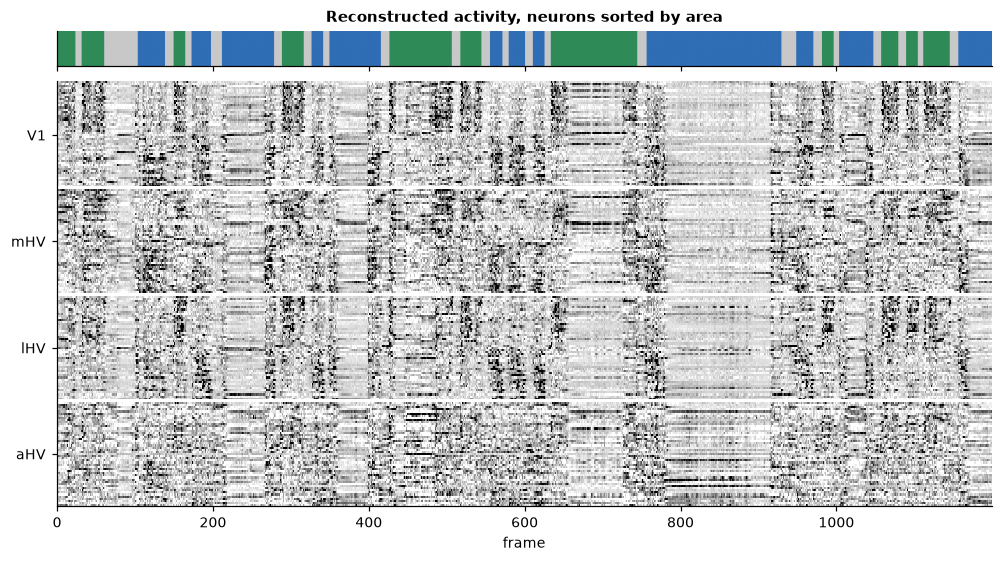

In [10]:
sample = neurons.dropna(subset="area").groupby("area").sample(500, random_state=0)
fit, shown = slice(0, 3000), slice(3000, 4200)
x = z.activity(session, sample.neuron.to_numpy(), fit)
role = frames.role.where((frames.position < 40) & frames.moving).iloc[fit].to_numpy()
leaf, circle = x[:, role == "leaf"], x[:, role == "circle"]
sample["dprime"] = 2 * (leaf.mean(1) - circle.mean(1)) / (leaf.std(1) + circle.std(1))
selective = sample.sort_values("dprime", ascending=False).groupby("area").nth([*range(25), *range(-25, 0)])
plot.raster(z.activity(session, selective.neuron.to_numpy(), shown), frames.iloc[shown], selective.area)

## Responses along the corridor

Averaging each area's neurons gives a population response along the corridor for leaf and circle trials. Those averages differ only a little, because each texture drives a different set of neurons. That is why the analysis measures discriminability neuron by neuron (d′), in `dprime.ipynb`.

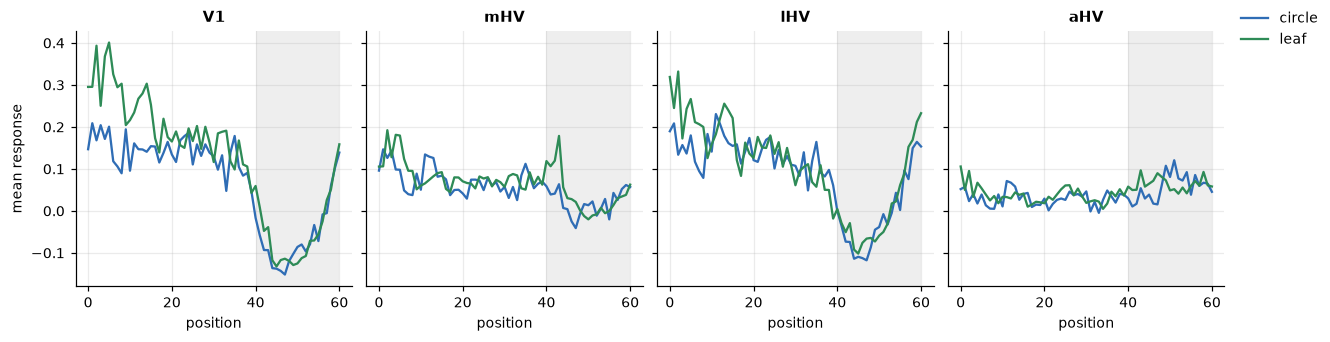

In [11]:
role = z.trials(session).set_index("trial").wall.map({z.sessions.set_index("session").leaf[session]: "leaf", z.sessions.set_index("session").circle[session]: "circle"})
population = {area: U[:, (neurons.area == area).to_numpy()].mean(1) @ V for area in plot.AREA}
profile = (
    frames.iloc[: V.shape[1]]
    .assign(role=lambda f: f.trial.map(role), position=lambda f: f.position.round(), **population)
    .query("moving and role.notna()")
    .melt(id_vars=["role", "position"], value_vars=list(plot.AREA), var_name="area", value_name="response")
    .groupby(["area", "role", "position"], as_index=False).response.mean()
)
plot.tuning(profile)